# Data-efficient MNIST classification in PyTorch

**Question:** how much does architecture and data augmentation matter when you only have 100 labeled examples per digit (1,000 images total)?

Experiments (all evaluated on the full 10k MNIST test set):
1. MLP trained on the 1k subset
2. Small CNN trained on the 1k subset
3. Small CNN on the 1k subset **with augmentation**
4. Small CNN on the full 60k training set (upper-bound reference)

Notes on method: the number of epochs and learning rate are fixed in advance, and I report the **final-epoch** test accuracy rather than the best epoch, so the test set is never used to pick a result. For a stronger version, add a validation split and run several seeds (see the last cell).

In [ ]:
# !pip install -r requirements.txt

In [3]:
import time, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print("Using device:", DEVICE)

BATCH_SIZE = 64
SAMPLES_PER_DIGIT = 100
EPOCHS = 20        # for the 1k-subset runs
FULL_EPOCHS = 5    # for the full 60k run
LR = 1e-3

Using device: mps


## 1. Data
Standard MNIST normalization uses mean 0.1307 and std 0.3081.

In [4]:
MEAN, STD = 0.1307, 0.3081

base_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((MEAN,), (STD,))])
# Augmentation is applied to the PIL image before ToTensor/Normalize
aug_tf = transforms.Compose([
    transforms.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    base_tf,
])

train_plain = datasets.MNIST("./mnist", train=True, download=True, transform=base_tf)
train_aug   = datasets.MNIST("./mnist", train=True, download=True, transform=aug_tf)
test_set    = datasets.MNIST("./mnist", train=False, download=True, transform=base_tf)

def balanced_indices(targets, n_per_class, seed=SEED):
    rng = np.random.default_rng(seed)
    targets = np.asarray(targets)
    idx = []
    for d in range(10):
        idx.extend(rng.choice(np.where(targets == d)[0], size=n_per_class, replace=False))
    return np.array(idx)

# Use .targets directly (fast) instead of looping over the dataset
sub_idx = balanced_indices(train_plain.targets.numpy(), SAMPLES_PER_DIGIT)
print("Subset size:", len(sub_idx))
print("Per-digit counts:", np.bincount(train_plain.targets.numpy()[sub_idx]))

100%|██████████| 9.91M/9.91M [00:07<00:00, 1.31MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.22MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 2.63MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.86MB/s]

Subset size: 1000
Per-digit counts: [100 100 100 100 100 100 100 100 100 100]


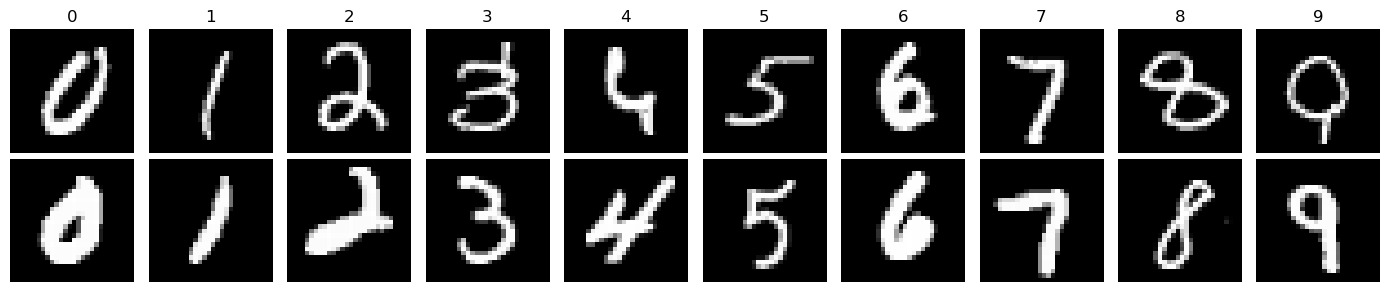

In [ ]:
def make_loader(ds, shuffle):
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=0)

loaders = {
    "subset":     make_loader(Subset(train_plain, sub_idx), True),
    "subset_aug": make_loader(Subset(train_aug, sub_idx), True),
    "full":       make_loader(train_plain, True),
}
test_loader = make_loader(test_set, False)

# quick look at the subset
fig, axes = plt.subplots(2, 10, figsize=(14, 3))
for d in range(10):
    ids = np.where(train_plain.targets.numpy()[sub_idx] == d)[0][:2]
    for r, i in enumerate(ids):
        img, _ = train_plain[sub_idx[i]]
        axes[r, d].imshow(img.squeeze(), cmap="gray"); axes[r, d].axis("off")
        if r == 0: axes[r, d].set_title(str(d))
plt.tight_layout(); plt.show()

## 2. Models
An MLP baseline and a small CNN (about 105k parameters).

In [6]:
class MLP(nn.Module):
    def __init__(self, hidden=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, 10),
        )
    def forward(self, x):
        return self.net(x)

class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.drop = nn.Dropout(0.25)
        self.fc1 = nn.Linear(32 * 7 * 7, 64)
        self.fc2 = nn.Linear(64, 10)
    def forward(self, x):
        x = F.max_pool2d(F.relu(self.conv1(x)), 2)   # 28 -> 14
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)   # 14 -> 7
        x = self.drop(torch.flatten(x, 1))
        x = F.relu(self.fc1(x))
        return self.fc2(x)

## 3. Training and evaluation

In [7]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    correct, total, loss_sum = 0, 0, 0.0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        out = model(x)
        loss_sum += F.cross_entropy(out, y, reduction="sum").item()
        correct += (out.argmax(1) == y).sum().item()
        total += y.size(0)
    return loss_sum / total, correct / total

def train(model, loader, epochs, lr=LR):
    model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"train_loss": [], "test_loss": [], "test_acc": []}
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train()
        running, n = 0.0, 0
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            loss = F.cross_entropy(model(x), y)
            loss.backward()
            opt.step()
            running += loss.item() * y.size(0)
            n += y.size(0)
        tl, ta = evaluate(model, test_loader)
        hist["train_loss"].append(running / n)
        hist["test_loss"].append(tl)
        hist["test_acc"].append(ta)
        print(f"  epoch {ep:2d}/{epochs}  train_loss {running/n:.4f}  test_loss {tl:.4f}  test_acc {ta:.4f}")
    hist["time_s"] = time.time() - t0
    return hist

## 4. Run the experiments

In [8]:
experiments = [
    ("MLP, 1k subset",                MLP,      "subset",     EPOCHS),
    ("CNN, 1k subset",                SmallCNN, "subset",     EPOCHS),
    ("CNN, 1k subset + augmentation", SmallCNN, "subset_aug", EPOCHS),
    ("CNN, full 60k",                 SmallCNN, "full",       FULL_EPOCHS),
]

results = {}
for name, cls, key, ep in experiments:
    print(f"\n== {name} ==")
    torch.manual_seed(SEED)
    model = cls()
    n_params = sum(p.numel() for p in model.parameters())
    hist = train(model, loaders[key], ep)
    results[name] = {"hist": hist, "params": n_params, "final_acc": hist["test_acc"][-1]}


== MLP, 1k subset ==
  epoch  1/20  train_loss 1.5743  test_loss 0.7088  test_acc 0.8039
  epoch  2/20  train_loss 0.4979  test_loss 0.4942  test_acc 0.8520
  epoch  3/20  train_loss 0.3547  test_loss 0.4659  test_acc 0.8549
  epoch  4/20  train_loss 0.2396  test_loss 0.4213  test_acc 0.8702
  epoch  5/20  train_loss 0.1665  test_loss 0.4257  test_acc 0.8719
  epoch  6/20  train_loss 0.1257  test_loss 0.4303  test_acc 0.8730
  epoch  7/20  train_loss 0.0896  test_loss 0.3989  test_acc 0.8893
  epoch  8/20  train_loss 0.0571  test_loss 0.4037  test_acc 0.8884
  epoch  9/20  train_loss 0.0363  test_loss 0.4310  test_acc 0.8843
  epoch 10/20  train_loss 0.0367  test_loss 0.4431  test_acc 0.8849
  epoch 11/20  train_loss 0.0238  test_loss 0.4434  test_acc 0.8867
  epoch 12/20  train_loss 0.0145  test_loss 0.4394  test_acc 0.8879
  epoch 13/20  train_loss 0.0103  test_loss 0.4419  test_acc 0.8911
  epoch 14/20  train_loss 0.0072  test_loss 0.4381  test_acc 0.8969
  epoch 15/20  train_loss 

## 5. Results

Experiment                            Params  Epochs  Time (s)  Final test acc
MLP, 1k subset                       269,322      20      16.3          89.36%
CNN, 1k subset                       105,866      20      24.5          93.89%
CNN, 1k subset + augmentation        105,866      20      18.1          96.58%
CNN, full 60k                        105,866       5      45.9          98.95%


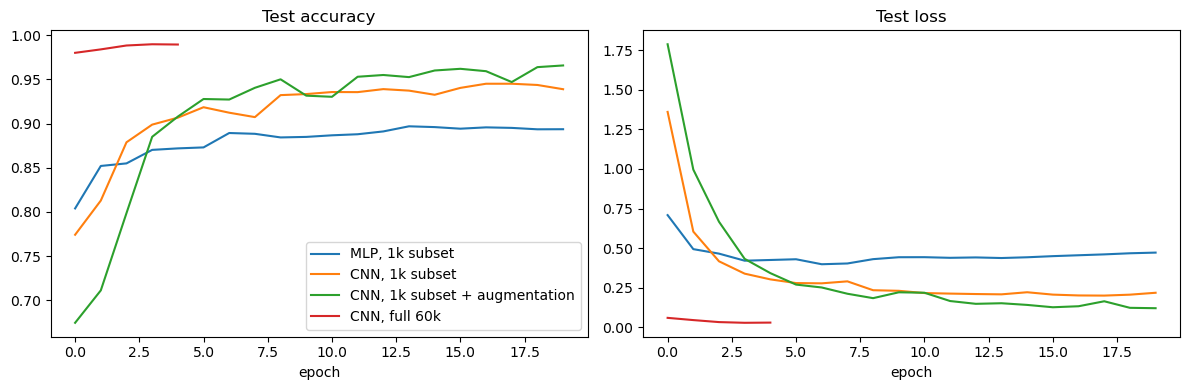

In [9]:
print(f"{'Experiment':34s} {'Params':>9s} {'Epochs':>7s} {'Time (s)':>9s} {'Final test acc':>15s}")
for name, r in results.items():
    print(f"{name:34s} {r['params']:>9,d} {len(r['hist']['test_acc']):>7d} "
          f"{r['hist']['time_s']:>9.1f} {r['final_acc']*100:>14.2f}%")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, r in results.items():
    ax[0].plot(r["hist"]["test_acc"], label=name)
    ax[1].plot(r["hist"]["test_loss"], label=name)
ax[0].set_title("Test accuracy"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].set_title("Test loss");     ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

## 6. Write-up

All results: single seed, 100 labeled images per digit (1,000 total), evaluated on the full 10k MNIST test set.

- **Architecture effect:** On the same 1k images, the CNN reached 93.89% test accuracy versus 89.36% for the MLP (+4.5 points), cutting the error rate from 10.64% to 6.11% (about 43% fewer errors). It did this with 2.5x fewer parameters (105,866 vs 269,322), which is consistent with convolutions' built-in spatial structure helping most when data is scarce.
- **Augmentation effect:** Random affine augmentation (small rotations, shifts, and scaling) raised the CNN from 93.89% to 96.58% (+2.7 points), cutting the error rate from 6.11% to 3.42% (about 44% fewer errors) at no extra parameter cost.
- **Gap to full data:** The CNN trained on all 60k images (5 epochs) reached 98.95%. With 1/60th of the labels, the augmented CNN gets within 2.4 points of it, and the un-augmented CNN is 5.1 points behind. Augmentation closed about half of that gap.
- **Cost:** The CNN has 105,866 parameters and the MLP 269,322. Wall-clock times were 16 to 25 seconds for the 20-epoch subset runs and 46 seconds for the 5-epoch full-data run. These are single measurements on one machine and include per-epoch test evaluation, so I don't read anything into the differences between the subset runs (for example, the augmented run finished faster than the plain one, which is likely noise or warm-up effects).
- **Limits:** Single seed and a single random subset, so the exact numbers will vary and I haven't measured by how much (the 2 to 5 point gaps are probably real, but this isn't tested). Hyperparameters (Adam, lr 1e-3, 20 epochs) were fixed up front and not tuned for any model, and there's no validation split. The MLP-vs-CNN comparison also changes architecture and parameter count together, so it doesn't isolate convolution as the cause. The full-data run used only 5 epochs, so 98.95% is not a tuned ceiling.


**Future Extensions**
1. Repeat each experiment over 5 seeds and report mean ± std (different subsets and initializations).
2. Hold out a validation split from the training data for any tuning.
3. Sweep subset size (10, 50, 100, 500 per digit) and plot a data-efficiency curve.
4. Try a pretrained backbone fine-tuned on the subset, or smaller/quantized variants, to connect to model efficiency.